In [ ]:
import pandas as pd
from datasets import load_dataset

# Load complete IMDB dataset
dataset = load_dataset("stanfordnlp/imdb")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [ ]:
df = pd.concat(
    [dataset["train"].to_pandas(),
     dataset["test"].to_pandas()],
    ignore_index=True
)

In [ ]:
df = df.rename(columns={"label": "labels"})


In [ ]:
print("\nMissing values")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Missing values
text      0
labels    0
dtype: int64

Number of duplicate rows:
418


In [ ]:
df["char_count"] = df["text"].astype(str).apply(len)
df["word_count"] = df["text"].astype(str).apply(lambda x: len(x.split()))
df["unique_word_count"] = df["text"].astype(str).apply(lambda x: len(set(x.lower().split())))
df["avg_word_length"] = df["text"].astype(str).apply(
    lambda x: sum(len(word) for word in x.split()) /
    max(len(x.split()), 1))

In [ ]:
print("\nText statistics:")
print(
    df[
        [
            "char_count",
            "word_count",
            "unique_word_count",
            "avg_word_length"
        ]
    ].describe()
)


Text statistics:
         char_count    word_count  unique_word_count  avg_word_length
count  50000.000000  50000.000000       50000.000000     50000.000000
mean    1309.431020    231.156940         148.049780         4.640676
std      989.728014    171.343997          88.837364         0.340731
min       32.000000      4.000000           4.000000         1.239865
25%      699.000000    126.000000          91.000000         4.417904
50%      970.000000    173.000000         120.000000         4.627006
75%     1590.250000    280.000000         180.000000         4.847458
max    13704.000000   2470.000000        1092.000000        12.290909


In [ ]:
import re

def clean_text(text):
    text = text.lower()

    # Fixed regex: added closing angular bracket '>' to match complete HTML tags
    text = re.sub(r"<.*?>"," ", text)

    text = re.sub(r"[^a-z\s]", " ", text)

    text = re.sub(r"\s+,", "", text).strip()

    return text

df["clean_text"] = df["text"].astype(str).apply(clean_text)

print("\nOriginal Review:")
print(df["text"].iloc[0][:500])
print("\nClean Review:")
print(df["clean_text"].iloc[0][:500])


Original Review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

Clean Review:
i rented i am curious yellow from my video store because of all the controversy that surrounded it when it was first released in       i also heard that at first it was seized by u s  customs if it ever tried to enter this country  therefore being a fan of films considered  controversial  i really had to see this for myself   the plot is centered around a young swedish drama student named lena who wants to learn everything she can about life  in particular she w

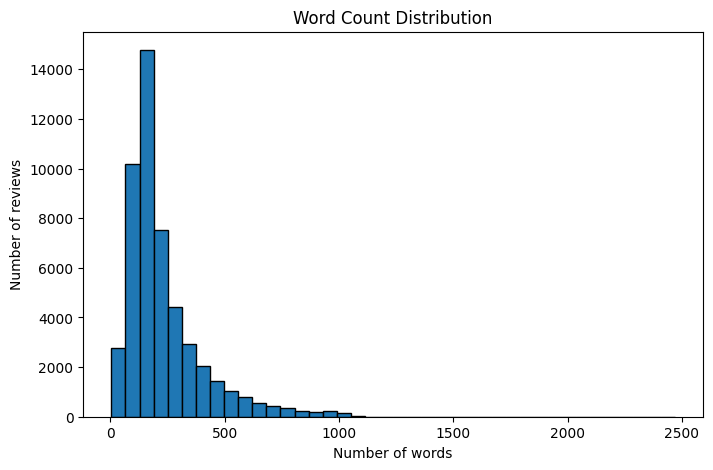

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))

plt.hist(df["word_count"], bins=40, edgecolor="black")
plt.xlabel("Number of words")
plt.ylabel("Number of reviews")
plt.title("Word Count Distribution")
plt.show()

In [ ]:
all_words = " ".join(df["clean_text"]).split()

print("Total number of words:", len(all_words))
print("Vocabulary size:", len(set(all_words)))

Total number of words: 11911303
Vocabulary size: 99426


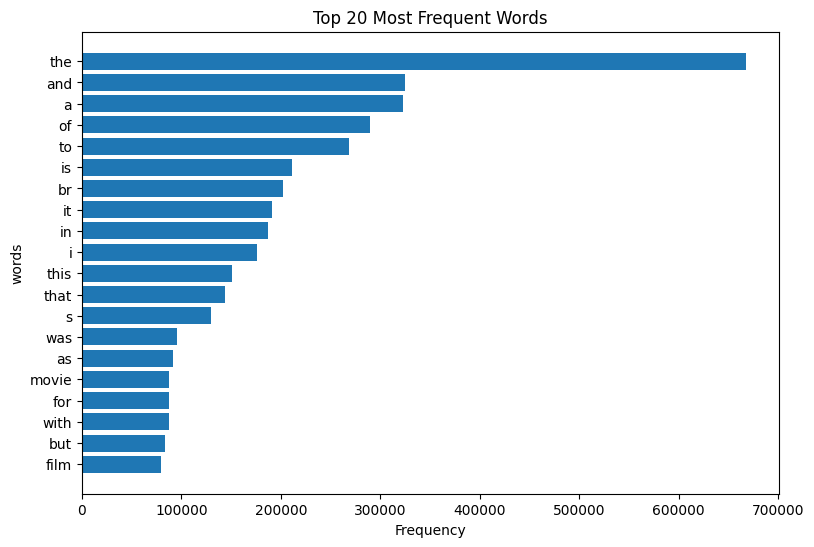

In [ ]:
from collections import Counter

word_freq = Counter(all_words)

top_words = word_freq.most_common(20)

words = [word for word, count in top_words]
counts = [count for word, count in top_words]

plt.figure(figsize=(9,6))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("words")
plt.title("Top 20 Most Frequent Words")
plt.show()

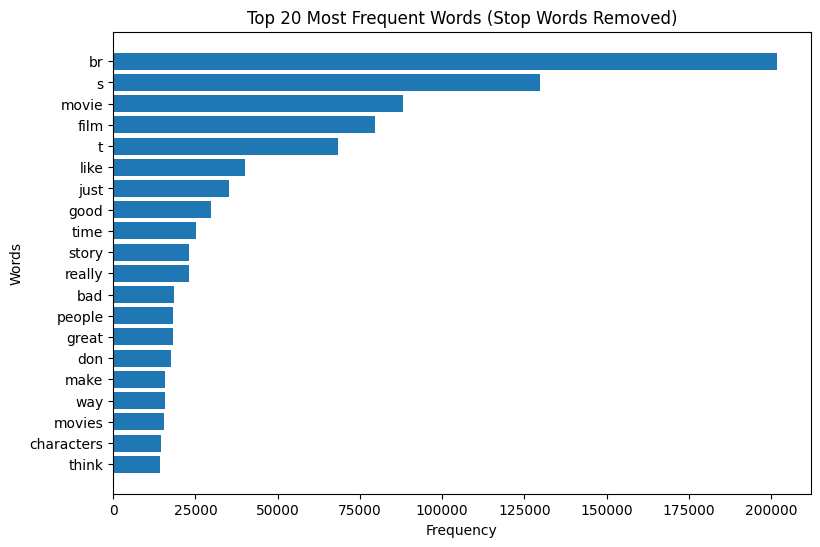

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer


vectorizer = CountVectorizer(
    stop_words="english"
)

vectorizer.fit(df["clean_text"])
stop_words = vectorizer.get_stop_words()

filtered_words = [word for word in all_words if word not in stop_words]

filtered_freq = Counter(filtered_words)

top_filtered = filtered_freq.most_common(20)

words = [word for word, count in top_filtered]
counts = [count for word, count in top_filtered]

plt.figure(figsize=(9,6))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Most Frequent Words (Stop Words Removed)")
plt.show()